# Procesamiento básico de imágenes

In [52]:
#importar bibliotecas necesarias
from pathlib import Path
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt

In [53]:
#Definir rutas
PROYECTO = Path("..")
DATA = PROYECTO / "data"
RAW = DATA / "raw"
ruta_imagen_gato = RAW / "Sphynx_176.jpg"
ruta_imagen_mascara = RAW / "Sphynx_176.png"

## Lectura y visualización

In [54]:
# Leer imagen en formato BGR
bgr = cv2.imread(str(ruta_imagen_gato), cv2.IMREAD_COLOR)

# Convertir BGR a RGB y a escala de grises
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

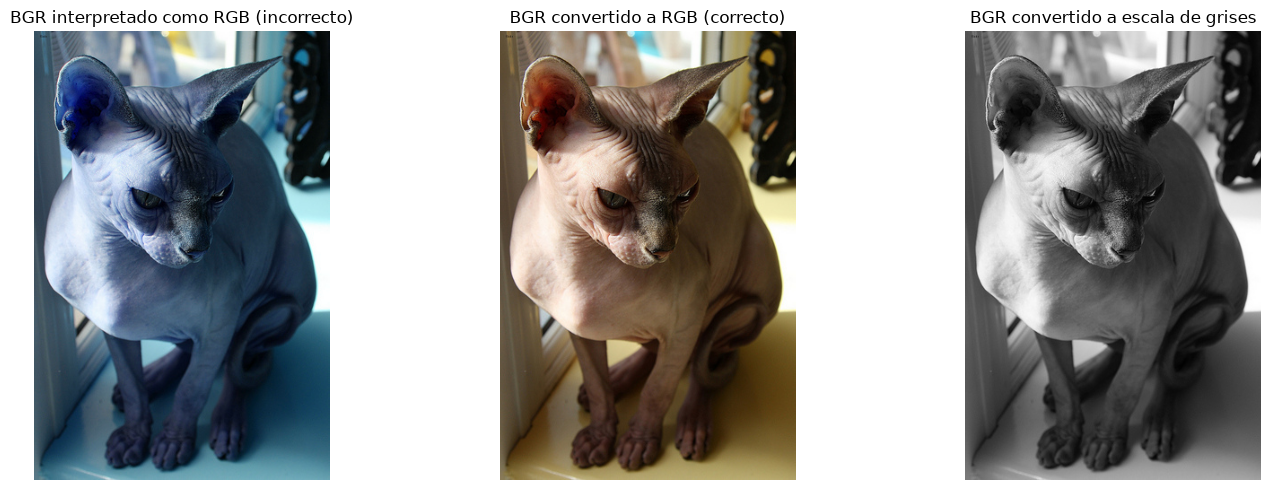

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(bgr)
axes[0].set_title("BGR interpretado como RGB (incorrecto)")
axes[1].imshow(rgb)
axes[1].set_title("BGR convertido a RGB (correcto)")
axes[2].imshow(gray, cmap="gray")
axes[2].set_title("BGR convertido a escala de grises")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

## Inspección de dimensiones, canales, tipos de datos y rangos de valores

In [56]:
# RGB
print("Dimensiones de la imagen RGB:", rgb.shape)
print("Tipo de datos de la imagen RGB:", rgb.dtype)
print("Valor máximo de la imagen RGB:", np.max(rgb))
print("Valor mínimo de la imagen RGB:", np.min(rgb))
print("--------------------------------")
# Escala de grises
print("Dimensiones de la imagen en escala de grises:", gray.shape)
print("Tipo de datos de la imagen en escala de grises:", gray.dtype)
print("Valor máximo de la imagen en escala de grises:", np.max(gray))
print("Valor mínimo de la imagen en escala de grises:", np.min(gray))

Dimensiones de la imagen RGB: (500, 330, 3)
Tipo de datos de la imagen RGB: uint8
Valor máximo de la imagen RGB: 255
Valor mínimo de la imagen RGB: 0
--------------------------------
Dimensiones de la imagen en escala de grises: (500, 330)
Tipo de datos de la imagen en escala de grises: uint8
Valor máximo de la imagen en escala de grises: 255
Valor mínimo de la imagen en escala de grises: 0


## Conversión de tipos, escalado de intensidades y estandarización

In [57]:
# Convertir a float32 y escalar a [0, 1]
rgb_float = rgb.astype(np.float32) / 255.0
gray_float = gray.astype(np.float32) / 255.0

# RGB
print("Dimensiones de la imagen RGB:", rgb_float.shape)
print("Tipo de datos de la imagen RGB:", rgb_float.dtype)
print("Valor máximo de la imagen RGB:", np.max(rgb_float))
print("Valor mínimo de la imagen RGB:", np.min(rgb_float))
print("--------------------------------")
# Escala de grises
print("Dimensiones de la imagen en escala de grises:", gray_float.shape)
print("Tipo de datos de la imagen en escala de grises:", gray_float.dtype)
print("Valor máximo de la imagen en escala de grises:", np.max(gray_float))
print("Valor mínimo de la imagen en escala de grises:", np.min(gray_float))


Dimensiones de la imagen RGB: (500, 330, 3)
Tipo de datos de la imagen RGB: float32
Valor máximo de la imagen RGB: 1.0
Valor mínimo de la imagen RGB: 0.0
--------------------------------
Dimensiones de la imagen en escala de grises: (500, 330)
Tipo de datos de la imagen en escala de grises: float32
Valor máximo de la imagen en escala de grises: 1.0
Valor mínimo de la imagen en escala de grises: 0.0


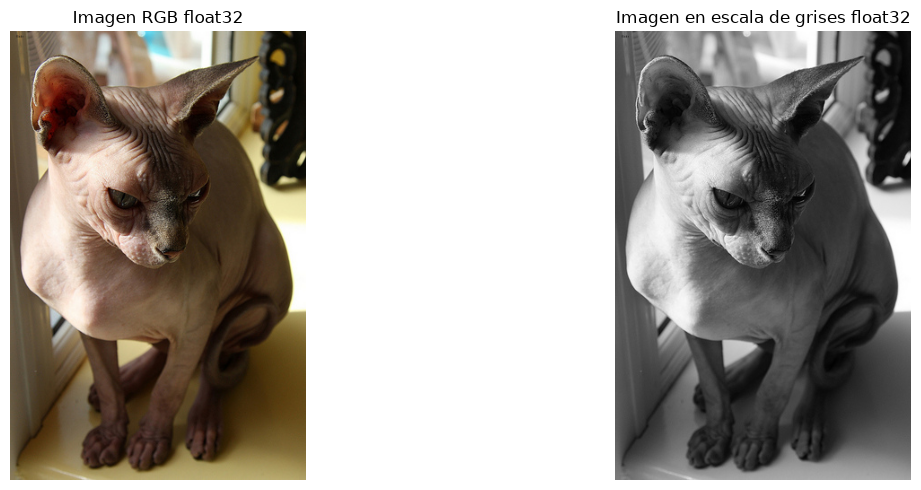

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].imshow(rgb_float)
axes[0].set_title('Imagen RGB float32')
axes[0].axis('off')

axes[1].imshow(gray_float, cmap='gray')
axes[1].set_title('Imagen en escala de grises float32')
axes[1].axis('off')
plt.tight_layout()
plt.show()

In [59]:
# Convertir a float32 y estandarizar a [0, 1] con media y desviación estándar
rgb_float_norm = (rgb_float - np.mean(rgb_float)) / np.std(rgb_float)
gray_float_norm = (gray_float - np.mean(gray_float)) / np.std(gray_float)

print("Dimensiones de la imagen RGB normalizada:", rgb_float_norm.shape)
print("Tipo de datos de la imagen RGB normalizada:", rgb_float_norm.dtype)
print("Valor máximo de la imagen RGB normalizada:", np.max(rgb_float_norm))
print("Valor mínimo de la imagen RGB normalizada:", np.min(rgb_float_norm))
print("--------------------------------")
print("Dimensiones de la imagen en escala de grises normalizada:", gray_float_norm.shape)
print("Tipo de datos de la imagen en escala de grises normalizada:", gray_float_norm.dtype)
print("Valor máximo de la imagen en escala de grises normalizada:", np.max(gray_float_norm))
print("Valor mínimo de la imagen en escala de grises normalizada:", np.min(gray_float_norm))


Dimensiones de la imagen RGB normalizada: (500, 330, 3)
Tipo de datos de la imagen RGB normalizada: float32
Valor máximo de la imagen RGB normalizada: 2.4591162
Valor mínimo de la imagen RGB normalizada: -1.381596
--------------------------------
Dimensiones de la imagen en escala de grises normalizada: (500, 330)
Tipo de datos de la imagen en escala de grises normalizada: float32
Valor máximo de la imagen en escala de grises normalizada: 2.4805124
Valor mínimo de la imagen en escala de grises normalizada: -1.4959576


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.381596..2.4591162].


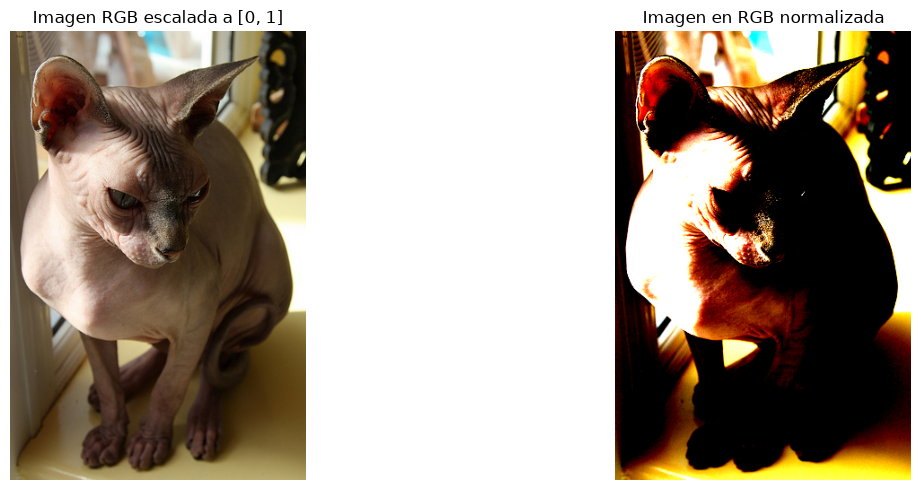

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].imshow(rgb_float)
axes[0].set_title('Imagen RGB escalada a [0, 1]')
axes[0].axis('off')
axes[1].imshow(rgb_float_norm, cmap='gray')
axes[1].set_title('Imagen en RGB normalizada')
axes[1].axis('off')
plt.tight_layout()
plt.show()


In [61]:
# Normalizar a [0, 1] para visualización
rgb_float_norm_visible = (rgb_float_norm - np.min(rgb_float_norm)) / (np.max(rgb_float_norm) - np.min(rgb_float_norm))
gray_float_norm_visible = (gray_float_norm - np.min(gray_float_norm)) / (np.max(gray_float_norm) - np.min(gray_float_norm))

print("Dimensiones de la imagen RGB normalizada para visualización:", rgb_float_norm_visible.shape)
print("Tipo de datos de la imagen RGB normalizada para visualización:", rgb_float_norm_visible.dtype)
print("Valor máximo de la imagen RGB normalizada para visualización:", np.max(rgb_float_norm_visible))
print("Valor mínimo de la imagen RGB normalizada para visualización:", np.min(rgb_float_norm_visible))
print("--------------------------------")
print("Dimensiones de la imagen en escala de grises normalizada para visualización:", gray_float_norm_visible.shape)
print("Tipo de datos de la imagen en escala de grises normalizada para visualización:", gray_float_norm_visible.dtype)
print("Valor máximo de la imagen en escala de grises normalizada para visualización:", np.max(gray_float_norm_visible))
print("Valor mínimo de la imagen en escala de grises normalizada para visualización:", np.min(gray_float_norm_visible))


Dimensiones de la imagen RGB normalizada para visualización: (500, 330, 3)
Tipo de datos de la imagen RGB normalizada para visualización: float32
Valor máximo de la imagen RGB normalizada para visualización: 1.0
Valor mínimo de la imagen RGB normalizada para visualización: 0.0
--------------------------------
Dimensiones de la imagen en escala de grises normalizada para visualización: (500, 330)
Tipo de datos de la imagen en escala de grises normalizada para visualización: float32
Valor máximo de la imagen en escala de grises normalizada para visualización: 1.0
Valor mínimo de la imagen en escala de grises normalizada para visualización: 0.0


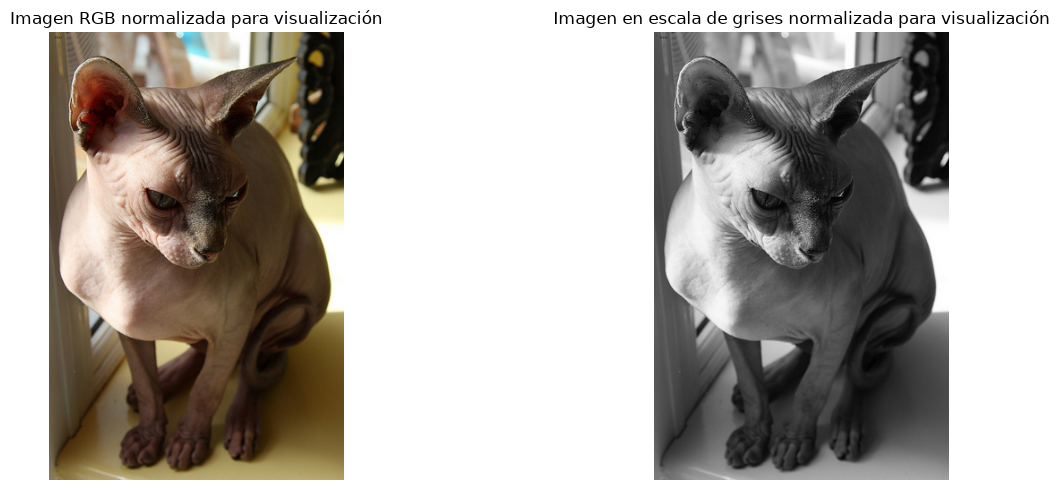

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].imshow(rgb_float_norm_visible)
axes[0].set_title('Imagen RGB normalizada para visualización')
axes[0].axis('off')
axes[1].imshow(gray_float_norm_visible, cmap='gray')
axes[1].set_title('Imagen en escala de grises normalizada para visualización')
axes[1].axis('off')
plt.tight_layout()
plt.show()


## Representación de imágenes mediante matrices y tensores

In [63]:
img = rgb_float  # Usar la imagen RGB float32 para la conversión
chw = np.transpose(img, (2, 0, 1))
batch = np.expand_dims(chw, axis=0)
print("OpenCV / NumPy (H, W, C):", img.shape)
print("Orden típico PyTorch (C, H, W):", chw.shape)
print("Lote de una imagen (B, C, H, W):", batch.shape)

OpenCV / NumPy (H, W, C): (500, 330, 3)
Orden típico PyTorch (C, H, W): (3, 500, 330)
Lote de una imagen (B, C, H, W): (1, 3, 500, 330)


In [64]:
batch = np.concatenate((batch, batch), axis=0)
print("Lote de dos imágenes (B, C, H, W):", batch.shape)

Lote de dos imágenes (B, C, H, W): (2, 3, 500, 330)


In [65]:
# Convertir imagen individual a tensor
tensor = torch.from_numpy(np.ascontiguousarray(chw))

# Convertir batch completo a tensor
batch_tensor = torch.from_numpy(np.ascontiguousarray(batch))

print("Tensor individual:", tensor.shape, tensor.dtype)
print("Tensor batch:", batch_tensor.shape, batch_tensor.dtype)

Tensor individual: torch.Size([3, 500, 330]) torch.float32
Tensor batch: torch.Size([2, 3, 500, 330]) torch.float32


## Redimensionamiento de imágenes y análisis de la relación de aspecto

In [66]:
def resize_con_padding(imagen, lado=256, interpolacion=cv2.INTER_AREA):
    alto, ancho = imagen.shape[:2]
    escala = lado / max(alto, ancho)
    nuevo_ancho = max(1, round(ancho * escala))
    nuevo_alto = max(1, round(alto * escala))
    redimensionada = cv2.resize(imagen, (nuevo_ancho, nuevo_alto),
                                interpolation=interpolacion)
    falta_x = lado - nuevo_ancho
    falta_y = lado - nuevo_alto
    izquierda = falta_x // 2
    derecha = falta_x - izquierda
    arriba = falta_y // 2
    abajo = falta_y - arriba
    salida = cv2.copyMakeBorder(
        redimensionada, arriba, abajo, izquierda, derecha,
        borderType=cv2.BORDER_CONSTANT, value=(0, 0, 0)
    )
    return salida, (nuevo_ancho, nuevo_alto), (arriba, abajo, izquierda, derecha)


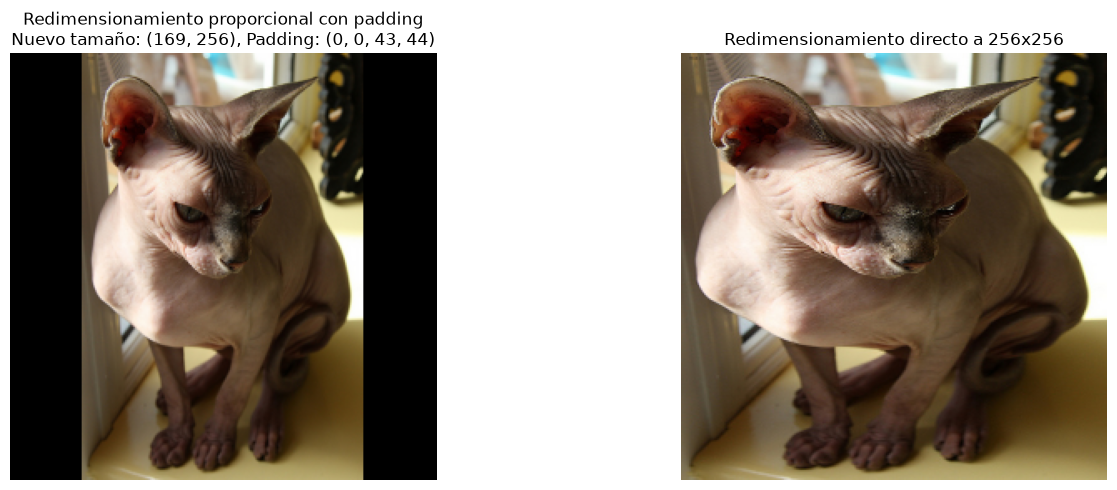

In [67]:
proporcional, tam, padding = resize_con_padding(rgb_float)
directo = cv2.resize(rgb_float, (256, 256), interpolation=cv2.INTER_LINEAR)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].imshow(proporcional)
axes[0].set_title(f'Redimensionamiento proporcional con padding\nNuevo tamaño: {tam}, Padding: {padding}')
axes[0].axis('off')
axes[1].imshow(directo)
axes[1].set_title('Redimensionamiento directo a 256x256')
axes[1].axis('off')
plt.tight_layout()
plt.show()

## Comparación de métodos de interpolación

In [68]:
# Interpolacion nearest neighbor
img_resized_nearest = cv2.resize(rgb_float, (256, 256), interpolation=cv2.INTER_NEAREST)
# Interpolacion bilineal
img_resized_bilinear = cv2.resize(rgb_float, (256, 256), interpolation=cv2.INTER_LINEAR)
# Interpolacion bicubica
img_resized_bicubic = cv2.resize(rgb_float, (256, 256), interpolation=cv2.INTER_CUBIC)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.056226425..1.0495857].


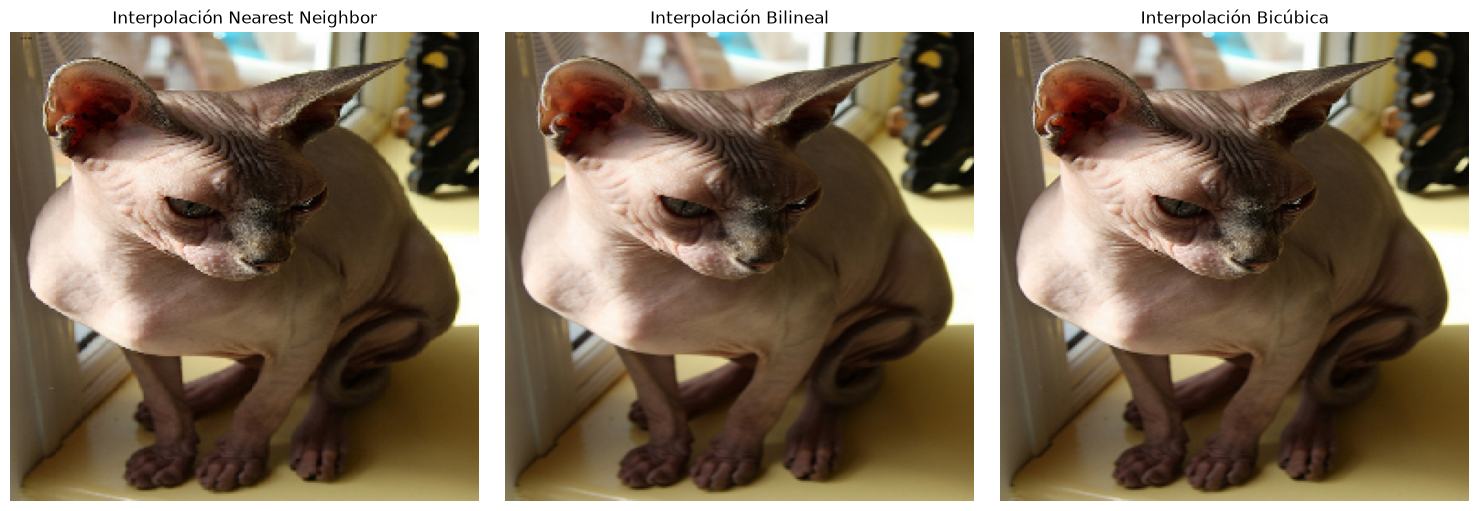

In [69]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_resized_nearest)
axes[0].set_title('Interpolación Nearest Neighbor')
axes[0].axis('off')
axes[1].imshow(img_resized_bilinear)
axes[1].set_title('Interpolación Bilineal')
axes[1].axis('off')
axes[2].imshow(img_resized_bicubic)
axes[2].set_title('Interpolación Bicúbica')
axes[2].axis('off')
plt.tight_layout()
plt.show()

## ¿Qué ocurre con la máscara?

In [70]:
# Leer mascara
img_mask = cv2.imread(str(ruta_imagen_mascara), cv2.IMREAD_GRAYSCALE)
# Nearest Neighbor
img_mask_nearest = cv2.resize(img_mask, (256, 256), interpolation=cv2.INTER_NEAREST)
# Bilineal
img_mask_bilinear = cv2.resize(img_mask, (256, 256), interpolation=cv2.INTER_LINEAR)
# Bicúbica
img_mask_bicubic = cv2.resize(img_mask, (256, 256), interpolation=cv2.INTER_CUBIC)


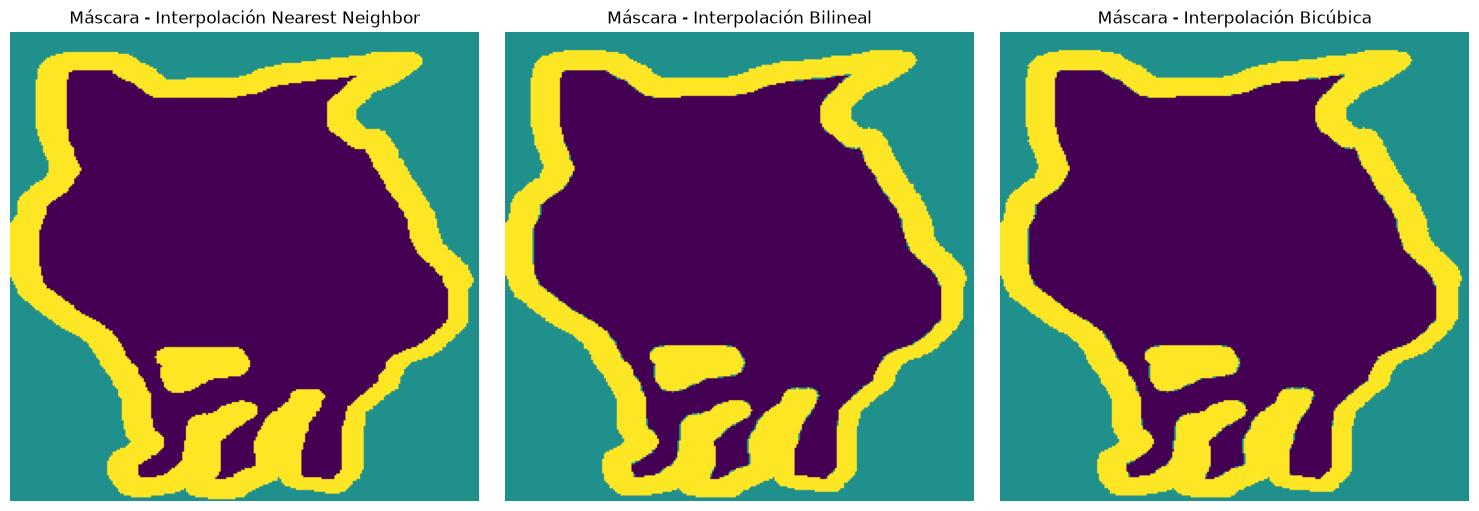

In [73]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_mask_nearest, cmap='viridis')
axes[0].set_title('Máscara - Interpolación Nearest Neighbor')
axes[0].axis('off')
axes[1].imshow(img_mask_bilinear, cmap='viridis')
axes[1].set_title('Máscara - Interpolación Bilineal')
axes[1].axis('off')
axes[2].imshow(img_mask_bicubic, cmap='viridis')
axes[2].set_title('Máscara - Interpolación Bicúbica')
axes[2].axis('off')
plt.tight_layout()
plt.show()